# Tour Interativo pelas 6 Etapas do `experimental-ml`

Este notebook demonstra um experimento completo de **classificação binária** passando por todas as **6 etapas oficiais**, exibindo diagnóstico da base, métricas por modelo/cenário, comparação estatística (Nadeau-Bengio / Wilcoxon), tabelas científicas em Markdown e gráfico **SVG** gerado em NumPy puro.

In [1]:
# Instalação automática apenas quando executado no Google Colab
import subprocess, sys
if "google.colab" in sys.modules:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "git+https://github.com/aleerangel/experimental-ml-framework.git",
    ])

In [2]:
# Helper de exibição rica (funciona em Jupyter/Colab e em Python puro)
def exibir_markdown(texto: str) -> None:
    try:
        from IPython.display import Markdown, display
        display(Markdown(texto))
    except ImportError:
        print(texto)

def exibir_svg(svg_bytes: bytes | str) -> None:
    svg_str = svg_bytes.decode("utf-8") if isinstance(svg_bytes, bytes) else svg_bytes
    try:
        from IPython.display import SVG, display
        display(SVG(svg_str))
    except ImportError:
        print(f"[Figura SVG gerada: {len(svg_str)} caracteres]")

## Etapa 1 — Ingestão Imutável, Diagnóstico e Saneamento

In [3]:
from pathlib import Path
import tempfile
import numpy as np

from experimental_ml.core.enums import MetricDirection, TaskType
from experimental_ml.data import (
    DatasetSchemaSpec,
    create_preparation_plan,
    load_dataset,
    profile_dataset,
    sanitize_dataset,
)

rng = np.random.default_rng(42)
n = 60
y = np.array([0] * 30 + [1] * 30)
x_informativa = rng.normal(loc=y * 1.4, scale=0.8)
x_ruido = rng.normal(loc=0.0, scale=1.0, size=n)

dados = {
    "biomarcador": x_informativa.tolist(),
    "ruido": x_ruido.tolist(),
    "alvo": y.tolist(),
}
schema = DatasetSchemaSpec(target_col="alvo", task_type=TaskType.BINARY_CLASSIFICATION)
bundle = load_dataset(dados, schema)
profile = profile_dataset(bundle)
plan = create_preparation_plan(profile, rules=[])
view = sanitize_dataset(bundle, profile, plan)

print(f"Amostras: {len(view.observation_ids)} | Dataset Hash: {view.dataset_hash[:16]}...")
for col_name, col_prof in profile.columns.items():
    if col_prof.numeric_stats is not None:
        st = col_prof.numeric_stats
        print(f"  - {col_name} ({col_prof.semantic_type.value}): média={st.mean:.3f}, std={st.std:.3f}, nulos={col_prof.n_missing}")
    else:
        print(f"  - {col_name} ({col_prof.semantic_type.value}): nulos={col_prof.n_missing}")

Amostras: 60 | Dataset Hash: e705558051ef7501...
  - biomarcador (NUMERIC_CONTINUOUS): média=0.752, std=0.974, nulos=0
  - ruido (NUMERIC_CONTINUOUS): média=-0.186, std=0.770, nulos=0
  - alvo (CATEGORICAL): média=0.500, std=0.504, nulos=0


## Etapas 2 e 3 — Cenários de Features e Modelos Competidores

Comparamos 2 modelos (`DummyMostFrequent` vs. `ClassificadorLinear`) em 2 cenários (`todas` vs. `apenas_biomarcador`).

In [4]:
from experimental_ml.features import FeatureScenario, ScenarioMode, validate_scenarios
from experimental_ml.models import (
    DummyBaselineModel,
    ModelCapabilities,
    ModelFamily,
    ModelSpec,
    validate_model_spec,
)

class ClassificadorLinearSimples:
    def __init__(self) -> None:
        self.w_ = None
        self.b_ = 0.0

    def fit(self, X: np.ndarray, y: np.ndarray) -> "ClassificadorLinearSimples":
        X_aug = np.column_stack([X, np.ones(len(X))])
        coef, *_ = np.linalg.lstsq(X_aug, y.astype(float), rcond=None)
        self.w_ = coef[:-1]
        self.b_ = float(coef[-1])
        return self

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        z = np.clip(X @ self.w_ + self.b_, -20.0, 20.0)
        p1 = 1.0 / (1.0 + np.exp(-z))
        return np.column_stack([1.0 - p1, p1])

    def predict(self, X: np.ndarray) -> np.ndarray:
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

cenarios = validate_scenarios([
    FeatureScenario(
        scenario_id="todas",
        name="Todas as Features",
        description="Biomarcador + ruído",
        scientific_justification="Cenário completo",
        mode=ScenarioMode.FIXED,
        selected_features=("biomarcador", "ruido"),
    ),
    FeatureScenario(
        scenario_id="somente_bio",
        name="Somente Biomarcador",
        description="Apenas variável informativa",
        scientific_justification="Cenário parcimonioso",
        mode=ScenarioMode.FIXED,
        selected_features=("biomarcador",),
    ),
], view)

modelos = [
    validate_model_spec(ModelSpec(
        model_id="dummy_freq",
        display_name="Dummy Majoritário",
        family=ModelFamily.BASELINE,
        estimator_factory=lambda seed=None: DummyBaselineModel(strategy="most_frequent"),
        capabilities=ModelCapabilities(supports_predict_proba=True),
        description="Baseline majoritário",
        scientific_justification="Referência nula",
    )),
    validate_model_spec(ModelSpec(
        model_id="linear_clf",
        display_name="Classificador Linear",
        family=ModelFamily.CLASSICAL_ML,
        estimator_factory=lambda seed=None: ClassificadorLinearSimples(),
        capabilities=ModelCapabilities(supports_predict_proba=True),
        description="Regressão linear logística simples",
        scientific_justification="Modelo paramétrico interpretável",
    )),
]
print(f"Validados {len(modelos)} modelos x {len(cenarios.scenarios)} cenários.")

Validados 2 modelos x 2 cenários.


## Etapa 4 — Particionamento (4A) e Execução Matricial (4B)

In [5]:
from experimental_ml.orchestration import load_cell_artifacts, run_experiment_matrix
from experimental_ml.validation import (
    EvaluationRegime,
    PartitionConfig,
    PartitionStrategy,
    build_partition_plan,
)

exp_dir = Path(tempfile.mkdtemp(prefix="expml_nb01_"))
part_plan = build_partition_plan(
    view,
    PartitionConfig(
        strategy=PartitionStrategy.STRATIFIED_KFOLD,
        regime=EvaluationRegime.CV_ONLY,
        n_splits=5,
        master_seed=42,
    ),
)
run_state = run_experiment_matrix(
    model_specs=modelos,
    scenarios=cenarios.scenarios,
    partition_plan=part_plan,
    sanitized_view=view,
    run_dir=exp_dir / "runs",
    metrics=("accuracy", "f1", "roc_auc"),
    master_seed=42,
    overwrite=True,
)
print(f"Matriz concluída: {run_state.completed_cells}/{run_state.total_cells} células | Falhas: {run_state.failed_cells}")

Matriz concluída: 20/20 células | Falhas: 0


## Etapa 5 — Consolidação, Comparação Estatística e Conclusão Estruturada

In [6]:
from experimental_ml.statistics import (
    ComparisonScope,
    ComparisonSpec,
    consolidate_descriptive,
    evaluate_method_suitability,
    run_statistical_comparisons,
    save_statistics_artifacts,
    synthesize_conclusions,
)

cells = [load_cell_artifacts(cid, exp_dir / "runs")[0] for cid in run_state.cell_statuses]
cons = consolidate_descriptive(cells, total_folds_per_config=len(part_plan.folds))
suit = evaluate_method_suitability(part_plan, cons)
comp = run_statistical_comparisons(
    cons, part_plan,
    ComparisonSpec(
        metrics_of_interest=("accuracy", "f1", "roc_auc"),
        metric_directions={
            "accuracy": MetricDirection.MAXIMIZE,
            "f1": MetricDirection.MAXIMIZE,
            "roc_auc": MetricDirection.MAXIMIZE,
        },
        comparison_scope=ComparisonScope.ALL_PAIRWISE,
        alpha=0.05,
    ),
    suit,
)
conc = synthesize_conclusions(cons, suit, comp, primary_metric="accuracy", primary_direction=MetricDirection.MAXIMIZE)
save_statistics_artifacts(exp_dir / "statistics", cons, suit, comp, conc, force=True)

print(f"Líder observado: {conc.observed_leader} | Evidência: {conc.statistical_evidence_status}")
print(f"Conclusão: {conc.narrative_text}")

Líder observado: ('linear_clf', 'todas') | Evidência: 0 of 6 comparison(s) reached adjusted significance (p_adj < 0.050); 6 comparison(s) had insufficient statistical evidence to reject H0 (non-significance does not imply equivalence).
Conclusão: On primary metric 'accuracy' (MAXIMIZE), observed leader is linear_clf/todas with mean=0.6167. 0 of 6 comparison(s) reached adjusted significance (p_adj < 0.050); 6 comparison(s) had insufficient statistical evidence to reject H0 (non-significance does not imply equivalence). Comparison dummy_freq/somente_bio vs dummy_freq/todas: diff=0.0000, t=0.0000, p_adj=1.0000 (Nadeau-Bengio), W=0.0, wx_p_adj=1.0000, d_z=0.0000 [NEGLIGIBLE], practical=NOT_CONFIGURED. Comparison dummy_freq/somente_bio vs linear_clf/somente_bio: diff=-0.1167, t=-2.3333, p_adj=0.4798 (Nadeau-Bengio), W=0.0, wx_p_adj=0.7500, d_z=-1.5652 [LARGE], practical=NOT_CONFIGURED. Comparison dummy_freq/somente_bio vs linear_clf/todas: diff=-0.1167, t=-2.3333, p_adj=0.4798 (Nadeau-Bengi

## Etapa 6 — Relatório Científico, Tabela Markdown e Gráfico SVG

### Tabela de Desempenho Preditivo

### Predictive Performance

| Model | Scenario | Metric | Status | Mean | SD | Median | IQR | Coverage |
| :--- | :--- | :--- | :---: | ---: | ---: | ---: | ---: | ---: |
| dummy_freq | somente_bio | accuracy | VALID | 0.5000 | 0.0000 | 0.5000 | 0.0000 | 100.00% |
| dummy_freq | somente_bio | f1 | VALID | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 100.00% |
| dummy_freq | somente_bio | roc_auc | VALID | 0.5000 | 0.0000 | 0.5000 | 0.0000 | 100.00% |
| dummy_freq | todas | accuracy | VALID | 0.5000 | 0.0000 | 0.5000 | 0.0000 | 100.00% |
| dummy_freq | todas | f1 | VALID | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 100.00% |
| dummy_freq | todas | roc_auc | VALID | 0.5000 | 0.0000 | 0.5000 | 0.0000 | 100.00% |
| linear_clf | somente_bio | accuracy | VALID | 0.6167 | 0.0745 | 0.6667 | 0.0833 | 100.00% |
| linear_clf | somente_bio | f1 | VALID | 0.7245 | 0.0376 | 0.7500 | 0.0441 | 100.00% |
| linear_clf | somente_bio | roc_auc | VALID | 0.9611 | 0.0248 | 0.9444 | 0.0278 | 100.00% |
| linear_clf | todas | accuracy | VALID | 0.6167 | 0.0745 | 0.6667 | 0.0833 | 100.00% |
| linear_clf | todas | f1 | VALID | 0.7245 | 0.0376 | 0.7500 | 0.0441 | 100.00% |
| linear_clf | todas | roc_auc | VALID | 0.9611 | 0.0248 | 0.9444 | 0.0278 | 100.00% |


### Tabela de Comparações Estatísticas

### Statistical Comparisons

| Config A | Config B | Metric | Diff | t (NB) | p_adj (NB) | p_adj (WX) | Cohen d_z | Practical Relevance |
| :--- | :--- | :--- | ---: | ---: | ---: | ---: | ---: | :--- |
| dummy_freq/somente_bio | dummy_freq/todas | accuracy | 0.0000 | 0.0000 | 1.0000 | 1.0000 | 0.0000 | NOT_CONFIGURED |
| dummy_freq/somente_bio | linear_clf/somente_bio | accuracy | -0.1167 | -2.3333 | 0.4798 | 0.7500 | -1.5652 | NOT_CONFIGURED |
| dummy_freq/somente_bio | linear_clf/todas | accuracy | -0.1167 | -2.3333 | 0.4798 | 0.7500 | -1.5652 | NOT_CONFIGURED |
| dummy_freq/todas | linear_clf/somente_bio | accuracy | -0.1167 | -2.3333 | 0.4798 | 0.7500 | -1.5652 | NOT_CONFIGURED |
| dummy_freq/todas | linear_clf/todas | accuracy | -0.1167 | -2.3333 | 0.4798 | 0.7500 | -1.5652 | NOT_CONFIGURED |
| linear_clf/somente_bio | linear_clf/todas | accuracy | 0.0000 | 0.0000 | 1.0000 | 1.0000 | 0.0000 | NOT_CONFIGURED |
| dummy_freq/somente_bio | dummy_freq/todas | f1 | 0.0000 | 0.0000 | 1.0000 | 1.0000 | 0.0000 | NOT_CONFIGURED |
| dummy_freq/somente_bio | linear_clf/somente_bio | f1 | -0.7245 | -28.7574 | 0.0001 | 0.3750 | -19.2910 | NOT_CONFIGURED |
| dummy_freq/somente_bio | linear_clf/todas | f1 | -0.7245 | -28.7574 | 0.0001 | 0.3750 | -19.2910 | NOT_CONFIGURED |
| dummy_freq/todas | linear_clf/somente_bio | f1 | -0.7245 | -28.7574 | 0.0001 | 0.3750 | -19.2910 | NOT_CONFIGURED |
| dummy_freq/todas | linear_clf/todas | f1 | -0.7245 | -28.7574 | 0.0001 | 0.3750 | -19.2910 | NOT_CONFIGURED |
| linear_clf/somente_bio | linear_clf/todas | f1 | 0.0000 | 0.0000 | 1.0000 | 1.0000 | 0.0000 | NOT_CONFIGURED |
| dummy_freq/somente_bio | dummy_freq/todas | roc_auc | 0.0000 | 0.0000 | 1.0000 | 1.0000 | 0.0000 | NOT_CONFIGURED |
| dummy_freq/somente_bio | linear_clf/somente_bio | roc_auc | -0.4611 | -27.6667 | 0.0001 | 0.3750 | -18.5594 | NOT_CONFIGURED |
| dummy_freq/somente_bio | linear_clf/todas | roc_auc | -0.4611 | -27.6667 | 0.0001 | 0.3750 | -18.5594 | NOT_CONFIGURED |
| dummy_freq/todas | linear_clf/somente_bio | roc_auc | -0.4611 | -27.6667 | 0.0001 | 0.3750 | -18.5594 | NOT_CONFIGURED |
| dummy_freq/todas | linear_clf/todas | roc_auc | -0.4611 | -27.6667 | 0.0001 | 0.3750 | -18.5594 | NOT_CONFIGURED |
| linear_clf/somente_bio | linear_clf/todas | roc_auc | 0.0000 | 0.0000 | 1.0000 | 1.0000 | 0.0000 | NOT_CONFIGURED |


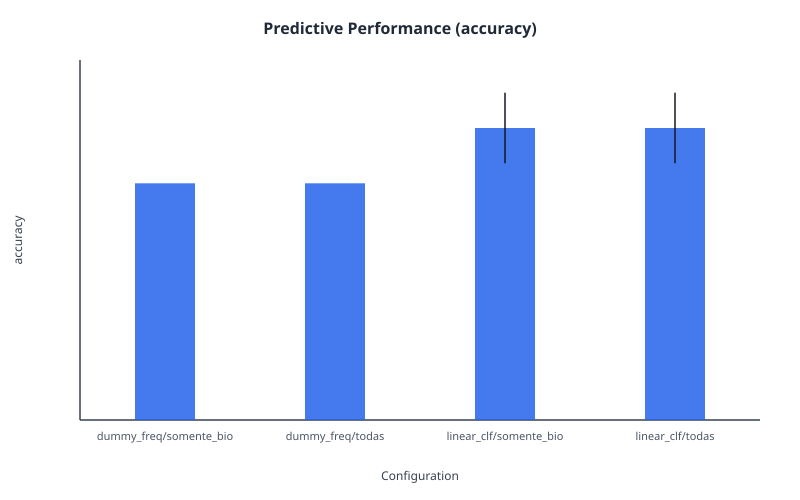

In [7]:
from experimental_ml.reporting import (
    ReportAudience,
    ReportContentSelection,
    ReportFamily,
    build_figure_spec,
    build_table_model,
    load_experiment_artifacts_readonly,
    render_figure,
    render_table_markdown,
    select_report_content,
)

loaded = load_experiment_artifacts_readonly(exp_dir)
sel = select_report_content(loaded, ReportContentSelection(audience=ReportAudience.FULL_LAB))

tabela_perf = build_table_model(ReportFamily.D_PREDICTIVE_PERFORMANCE, loaded, sel)
exibir_markdown("### Tabela de Desempenho Preditivo\n\n" + render_table_markdown(tabela_perf))

tabela_stat = build_table_model(ReportFamily.E_STATISTICAL_COMPARISONS, loaded, sel)
exibir_markdown("### Tabela de Comparações Estatísticas\n\n" + render_table_markdown(tabela_stat))

fig = build_figure_spec(ReportFamily.D_PREDICTIVE_PERFORMANCE, loaded, sel)
exibir_svg(render_figure(fig, fmt="svg"))